# Análise Exploratória: Olist (Data Warehouse DuckDB)

Dez perguntas, duas por tópico (Vendas, Logística, Satisfação, Financeiro, Clientes e pagamentos), cada uma com **consulta SQL**,
**gráfico** e **conclusão de negócio**. As consultas ficam em `sql/analytics.sql` e rodam sobre a camada **gold**.
Os textos de conclusão são gerados a partir dos resultados, para nunca divergirem dos dados.

**Receita = soma de `price` (sem frete) de pedidos não cancelados/indisponíveis. Receita não é lucro: o dataset não tem custos.**

> Para executar do zero: `make run` (cria o ambiente, instala as dependências, roda o ETL e este notebook) ou abra no Jupyter/Colab
> depois de `python src/pipeline.py`.

## Justificativa da modelagem

O warehouse tem **três camadas** (bronze, silver e gold) e a gold é um **modelo estrela**:

- **Bronze** guarda a cópia fiel dos 9 CSVs (tudo `VARCHAR`), para rastrear qualquer número até a origem.
- **Silver** limpa e tipa (datas, valores, duplicidades, categorias traduzidas) com 21 regras documentadas em `docs/data_quality.md`.
- **Gold** organiza em **fatos** (`fact_order_items`, `fact_payments` e a derivada `fact_orders`, com `delivery_days`, `delay_days` e `is_late`)
  e **dimensões** (`dim_customer`, `dim_seller`, `dim_product`, `dim_date`).

**Por quê:** separar as camadas torna cada transformação auditável e reexecutável. O modelo estrela simplifica as consultas
(poucos joins, nomes de negócio) e evita erros de duplicação de linhas, como a avaliação repetida por pedido ou várias coordenadas por CEP.

In [1]:
import re, sys
from pathlib import Path
import duckdb, matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CHARTS = ROOT / "reports" / "charts"; CHARTS.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(ROOT / "data/warehouse/olist.duckdb"), read_only=True)
QUERIES = dict(re.findall(r"-- name: (\w+)\n(.*?)(?=\n-- name:|\Z)", (ROOT / "sql/analytics.sql").read_text(), re.S))
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})

def q(name):
    sql = QUERIES[name]; print(sql.strip()); return con.execute(sql).df()
def save(fig, name):
    fig.tight_layout(); fig.savefig(CHARTS / f"{name}.png", dpi=130); plt.show()
def conclusao(*linhas):
    display(Markdown(("**Conclusão de negócio**\n\n" + "\n".join(f"- {l}" for l in linhas)).replace("$", "\\$")))

## Tópico 1: Vendas

### 1a. Quais são as 10 categorias com maior receita?

-- Vendas (1A): quais são as 10 categorias com maior receita?
SELECT p.category_en AS categoria,
       round(sum(f.price), 2) AS receita,
       count(DISTINCT f.order_id) AS pedidos
FROM gold.fact_order_items f
JOIN gold.dim_product p USING (product_id)
WHERE f.is_revenue
GROUP BY 1
ORDER BY receita DESC
LIMIT 10;


,categoria,receita,pedidos
0,health_beauty,1255695.13,8800
1,watches_gifts,1198185.21,5604
2,bed_bath_table,1035964.06,9399
3,sports_leisure,979740.92,7673
4,computers_accessories,904322.02,6654
5,furniture_decor,727465.05,6425
6,housewares,626825.80,5847
7,cool_stuff,620770.49,3616
8,auto,586585.73,3872
9,garden_tools,481009.94,3505


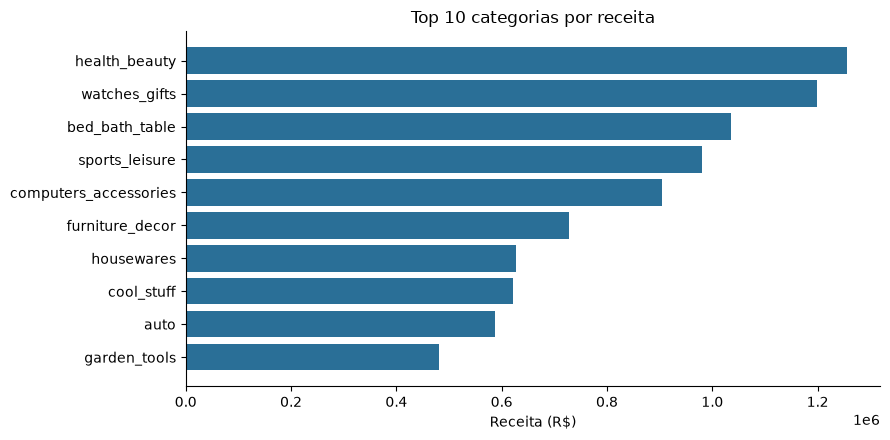

**Conclusão de negócio**

- A categoria líder é **health_beauty**, com R\$ 1,255,695.
- As 3 maiores categorias somam 25.9% da receita total (R\$ 13,494,401).
- A receita é concentrada em poucas categorias: ações de estoque e marketing devem priorizá-las.

In [2]:
df = q("q1_top10_categorias_receita"); display(df)
fig, ax = plt.subplots(); ax.barh(df.categoria[::-1], df.receita[::-1], color="#2a6f97")
ax.set_xlabel("Receita (R$)"); ax.set_title("Top 10 categorias por receita"); save(fig, "01a_top10_categorias_receita")
tot = con.execute("SELECT sum(price) FROM gold.fact_order_items WHERE is_revenue").fetchone()[0]
top3 = df.receita.head(3).sum()
conclusao(f"A categoria líder é **{df.categoria[0]}**, com R$ {df.receita[0]:,.0f}.",
          f"As 3 maiores categorias somam {100*top3/float(tot):.1f}% da receita total (R$ {float(tot):,.0f}).",
          "A receita é concentrada em poucas categorias: ações de estoque e marketing devem priorizá-las.")

### 1b. Como a receita total varia mês a mês?

-- Vendas (1B): como a receita total varia mês a mês? (jan/2017 a ago/2018: meses completos)
SELECT d.year_month AS mes,
       round(sum(f.price), 2) AS receita,
       count(DISTINCT f.order_id) AS pedidos
FROM gold.fact_order_items f
JOIN gold.dim_date d ON d.date_key = f.purchase_date
WHERE f.is_revenue AND d.year_month BETWEEN '2017-01' AND '2018-08'
GROUP BY 1
ORDER BY 1;


,mes,receita,pedidos
0,2017-01,120098.27,787
1,2017-02,244959.35,1718
2,2017-03,368341.32,2617
3,2017-04,353842.98,2377
4,2017-05,503159.19,3640
5,2017-06,429916.61,3205
6,2017-07,492287.30,3946
7,2017-08,568245.79,4272
8,2017-09,621415.91,4227
9,2017-10,660179.62,4547


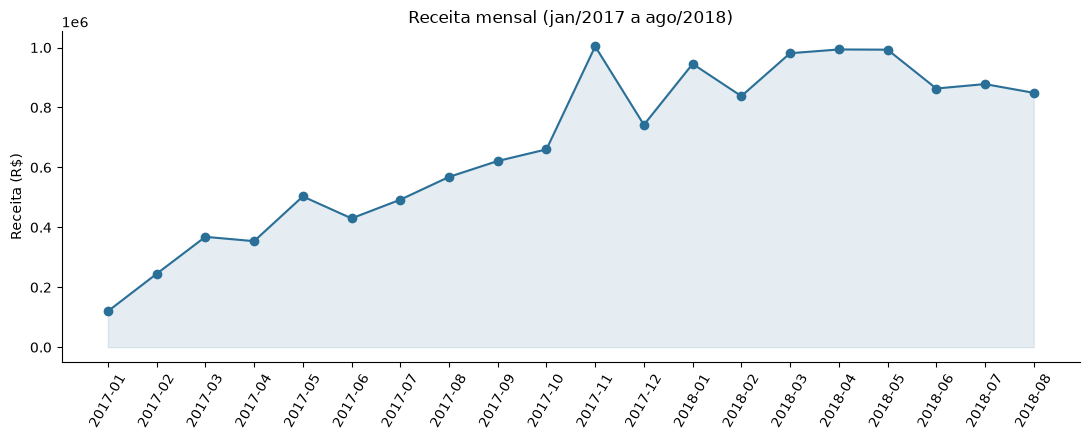

**Conclusão de negócio**

- A receita cresceu de R\$ 120,098 em 2017-01 para R\$ 848,860 em 2018-08.
- O pico foi em **2017-11** (R\$ 1,003,862), mês da Black Friday.
- Em 2018 a receita se estabiliza em torno de R\$ 917,630 por mês: o ritmo de expansão desacelerou.

In [3]:
df = q("q1b_receita_mensal"); display(df)
fig, ax = plt.subplots(figsize=(11, 4.5)); ax.plot(df.mes, df.receita, marker="o", color="#2a6f97")
ax.fill_between(df.mes, df.receita, alpha=.12, color="#2a6f97"); ax.set_ylabel("Receita (R$)"); ax.set_title("Receita mensal (jan/2017 a ago/2018)")
ax.tick_params(axis="x", rotation=60); save(fig, "01b_receita_mensal")
pico = df.loc[df.receita.idxmax()]; h = df.query("mes >= '2018-01'")
conclusao(f"A receita cresceu de R$ {df.receita.iloc[0]:,.0f} em {df.mes.iloc[0]} para R$ {df.receita.iloc[-1]:,.0f} em {df.mes.iloc[-1]}.",
          f"O pico foi em **{pico.mes}** (R$ {pico.receita:,.0f}), mês da Black Friday.",
          f"Em 2018 a receita se estabiliza em torno de R$ {h.receita.mean():,.0f} por mês: o ritmo de expansão desacelerou.")

## Tópico 2: Logística

### 2a. Qual o tempo médio de entrega, em dias, por estado?

-- Logística (2A): qual o tempo médio de entrega, em dias, por estado do cliente?
-- Só pedidos 'delivered' com datas válidas (delivery_days nulo caso contrário).
SELECT c.state AS uf,
       round(avg(o.delivery_days), 1) AS dias,
       count(*) AS pedidos
FROM gold.fact_orders o
JOIN gold.dim_customer c USING (customer_id)
WHERE o.delivery_days IS NOT NULL
GROUP BY 1
ORDER BY dias DESC;


,uf,dias,pedidos
0,RR,29.3,41
1,AP,27.2,67
2,AM,26.4,145
3,AL,24.5,397
4,PA,23.7,945
5,SE,21.5,334
6,MA,21.5,714
7,CE,21.2,1278
8,AC,21.0,80
9,PB,20.4,517


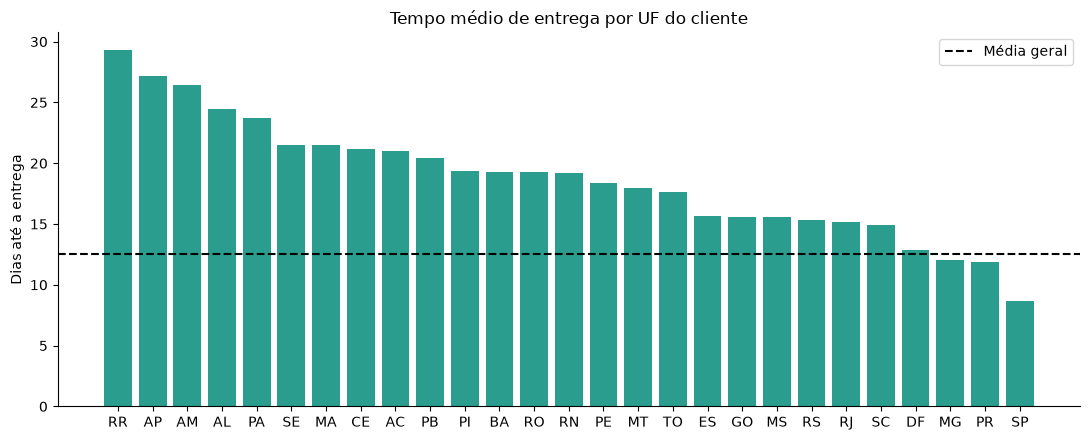

**Conclusão de negócio**

- O prazo médio nacional é de 12.5 dias.
- A entrega mais lenta é em **RR** (29.3 dias) e a mais rápida em **SP** (8.7 dias).
- Estados distantes dos centros de distribuição esperam bem mais; vale avaliar centros regionais ou transportadoras locais.

In [4]:
df = q("q2a_prazo_uf"); display(df)
fig, ax = plt.subplots(figsize=(11, 4.5)); ax.bar(df.uf, df.dias, color="#2a9d8f")
ax.axhline(float(con.execute("SELECT avg(delivery_days) FROM gold.fact_orders").fetchone()[0]), color="k", ls="--", label="Média geral")
ax.set_ylabel("Dias até a entrega"); ax.set_title("Tempo médio de entrega por UF do cliente"); ax.legend(); save(fig, "02a_prazo_medio_uf")
geral = float(con.execute("SELECT avg(delivery_days) FROM gold.fact_orders").fetchone()[0])
conclusao(f"O prazo médio nacional é de {geral:.1f} dias.",
          f"A entrega mais lenta é em **{df.uf.iloc[0]}** ({df.dias.iloc[0]:.1f} dias) e a mais rápida em **{df.uf.iloc[-1]}** ({df.dias.iloc[-1]:.1f} dias).",
          "Estados distantes dos centros de distribuição esperam bem mais; vale avaliar centros regionais ou transportadoras locais.")

### 2b. Qual a porcentagem de pedidos entregues com atraso?

-- Logística (2B): qual a porcentagem de pedidos entregues com atraso (global e por UF)?
SELECT c.state AS uf,
       count(*) AS pedidos_entregues,
       count(*) FILTER (WHERE o.is_late) AS pedidos_atrasados,
       round(100.0 * count(*) FILTER (WHERE o.is_late) / count(*), 2) AS pct_atraso
FROM gold.fact_orders o
JOIN gold.dim_customer c USING (customer_id)
WHERE o.is_late IS NOT NULL
GROUP BY ROLLUP (c.state)
ORDER BY uf NULLS FIRST;


,uf,pedidos_entregues,pedidos_atrasados,pct_atraso
0,NaN,96282,6532,6.78
1,AC,80,3,3.75
2,AL,397,85,21.41
3,AM,145,4,2.76
4,AP,67,2,2.99
5,BA,3252,395,12.15
6,CE,1278,176,13.77
7,DF,2077,118,5.68
8,ES,1989,214,10.76
9,GO,1951,128,6.56


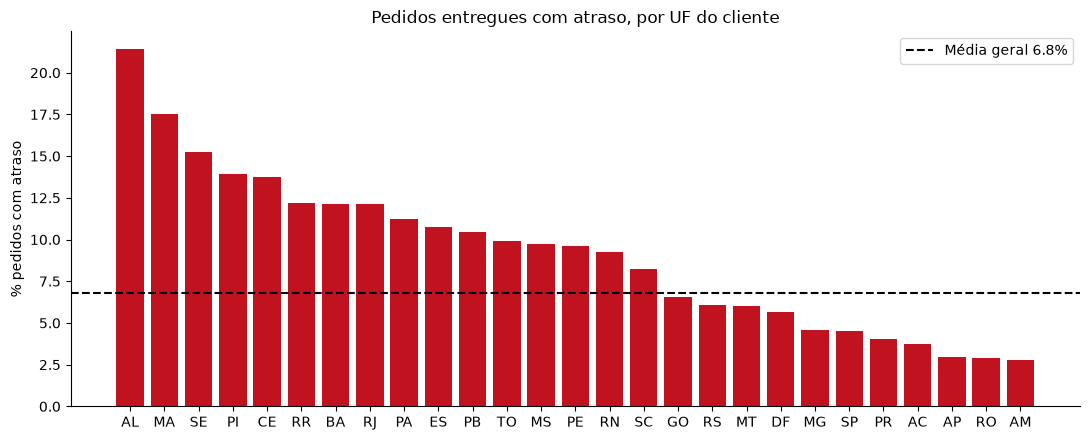

**Conclusão de negócio**

- 6.8% dos 96,282 pedidos entregues chegaram após a data estimada.
- A UF com maior atraso é **AL** (21.4%); a menor é **AM** (2.8%).
- Estados com atraso acima da média pedem revisão de transportadoras ou de prazos prometidos.

In [5]:
df = q("q2_pct_atraso"); display(df)
g = df[df.uf.notna()].sort_values("pct_atraso", ascending=False)
glob = df[df.uf.isna()].iloc[0]
fig, ax = plt.subplots(figsize=(11, 4.5)); ax.bar(g.uf, g.pct_atraso, color="#c1121f")
ax.axhline(glob.pct_atraso, color="k", ls="--", label=f"Média geral {glob.pct_atraso:.1f}%")
ax.set_ylabel("% pedidos com atraso"); ax.set_title("Pedidos entregues com atraso, por UF do cliente")
ax.legend(); save(fig, "02b_pct_atraso_uf")
conclusao(f"{glob.pct_atraso:.1f}% dos {int(glob.pedidos_entregues):,} pedidos entregues chegaram após a data estimada.",
          f"A UF com maior atraso é **{g.uf.iloc[0]}** ({g.pct_atraso.iloc[0]:.1f}%); a menor é **{g.uf.iloc[-1]}** ({g.pct_atraso.iloc[-1]:.1f}%).",
          "Estados com atraso acima da média pedem revisão de transportadoras ou de prazos prometidos.")

## Tópico 3: Satisfação do cliente

### 3a. Como se distribuem as notas de 1 a 5?

-- Satisfação (3A): como se distribuem as notas de 1 a 5? (1 avaliação por pedido, a mais recente)
SELECT review_score AS nota,
       count(*) AS pedidos,
       round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
FROM gold.fact_orders
WHERE review_score IS NOT NULL
GROUP BY 1
ORDER BY 1;


,nota,pedidos,pct
0,1,11363,11.52
1,2,3131,3.17
2,3,8133,8.24
3,4,19038,19.29
4,5,57008,57.77


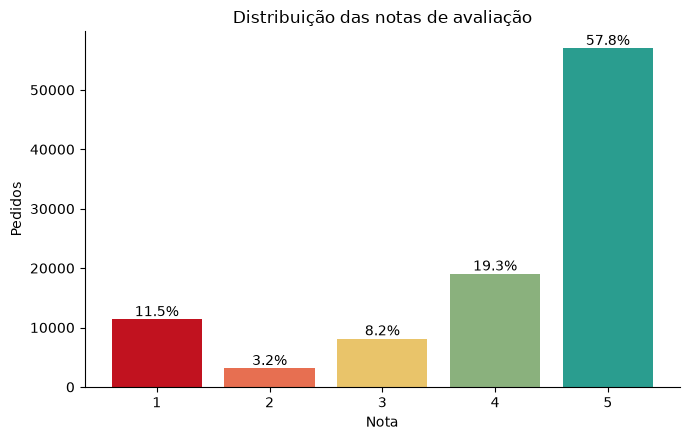

**Conclusão de negócio**

- A nota 5 é a mais comum (57.8% das avaliações) e a nota 4 vem em seguida (19.3%).
- A distribuição tem formato de J: a maioria está satisfeita, mas 14.7% dos clientes deram nota 1 ou 2.
- Entender as causas das notas 1 (atraso, produto errado) é o caminho mais curto para subir a média.

In [6]:
df = q("q3a_distribuicao_notas"); display(df)
fig, ax = plt.subplots(figsize=(7, 4.5)); b = ax.bar(df.nota.astype(str), df.pedidos, color=["#c1121f", "#e76f51", "#e9c46a", "#8ab17d", "#2a9d8f"])
for r, p in zip(b, df.pct): ax.text(r.get_x() + r.get_width() / 2, r.get_height(), f"{p:.1f}%", ha="center", va="bottom")
ax.set_xlabel("Nota"); ax.set_ylabel("Pedidos"); ax.set_title("Distribuição das notas de avaliação"); save(fig, "03a_distribuicao_notas")
pc = df.set_index("nota").pct
conclusao(f"A nota 5 é a mais comum ({pc[5]:.1f}% das avaliações) e a nota 4 vem em seguida ({pc[4]:.1f}%).",
          f"A distribuição tem formato de J: a maioria está satisfeita, mas {pc[1]+pc[2]:.1f}% dos clientes deram nota 1 ou 2.",
          "Entender as causas das notas 1 (atraso, produto errado) é o caminho mais curto para subir a média.")

### 3b. Pedidos atrasados têm nota média menor que os entregues no prazo?

-- Satisfação (3B): pedidos atrasados têm nota média menor que os entregues no prazo?
SELECT CASE WHEN is_late THEN 'Com atraso' ELSE 'No prazo' END AS situacao,
       count(*) AS pedidos,
       round(avg(review_score), 2) AS nota_media
FROM gold.fact_orders
WHERE is_late IS NOT NULL AND review_score IS NOT NULL
GROUP BY 1
ORDER BY 1;


,situacao,pedidos,nota_media
0,Com atraso,6379,2.27
1,No prazo,89258,4.29


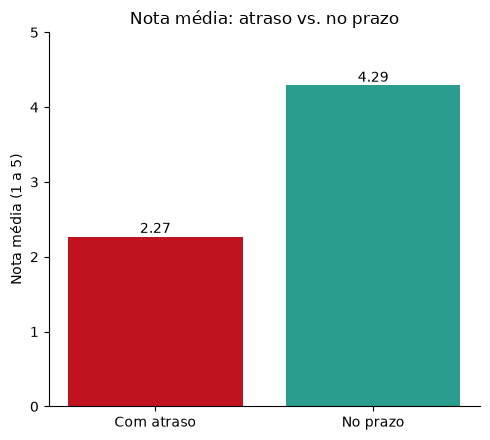

**Conclusão de negócio**

- Pedidos com atraso têm nota média 2.27 contra 4.29 dos entregues no prazo (diferença de 2.02 ponto(s)).
- O atraso está associado a pior satisfação; é correlação, outros fatores também influenciam a nota.
- Reduzir atrasos é uma alavanca direta para melhorar a avaliação dos clientes.

In [7]:
df = q("q3_nota_atraso"); display(df)
fig, ax = plt.subplots(figsize=(5, 4.5)); ax.bar(df.situacao, df.nota_media, color=["#c1121f", "#2a9d8f"])
ax.set_ylim(0, 5); ax.set_ylabel("Nota média (1 a 5)"); ax.set_title("Nota média: atraso vs. no prazo")
for i, v in enumerate(df.nota_media): ax.text(i, v + .05, f"{v:.2f}", ha="center")
save(fig, "03b_nota_media_atraso")
a = df.set_index("situacao").nota_media
conclusao(f"Pedidos com atraso têm nota média {a['Com atraso']:.2f} contra {a['No prazo']:.2f} dos entregues no prazo "
          f"(diferença de {a['No prazo']-a['Com atraso']:.2f} ponto(s)).",
          "O atraso está associado a pior satisfação; é correlação, outros fatores também influenciam a nota.",
          "Reduzir atrasos é uma alavanca direta para melhorar a avaliação dos clientes.")

## Tópico 4: Financeiro

### 4a. Qual a receita por categoria e sua participação no total?

-- Financeiro (4A): qual a receita por categoria e sua participação no total?
SELECT p.category_en AS categoria,
       round(sum(f.price), 2) AS receita,
       round(100.0 * sum(f.price) / sum(sum(f.price)) OVER (), 2) AS pct
FROM gold.fact_order_items f
JOIN gold.dim_product p USING (product_id)
WHERE f.is_revenue
GROUP BY 1
ORDER BY receita DESC;


,categoria,receita,pct
0,health_beauty,1255695.13,9.31
1,watches_gifts,1198185.21,8.88
2,bed_bath_table,1035964.06,7.68
3,sports_leisure,979740.92,7.26
4,computers_accessories,904322.02,6.70
5,furniture_decor,727465.05,5.39
6,housewares,626825.80,4.65
7,cool_stuff,620770.49,4.60
8,auto,586585.73,4.35
9,garden_tools,481009.94,3.56


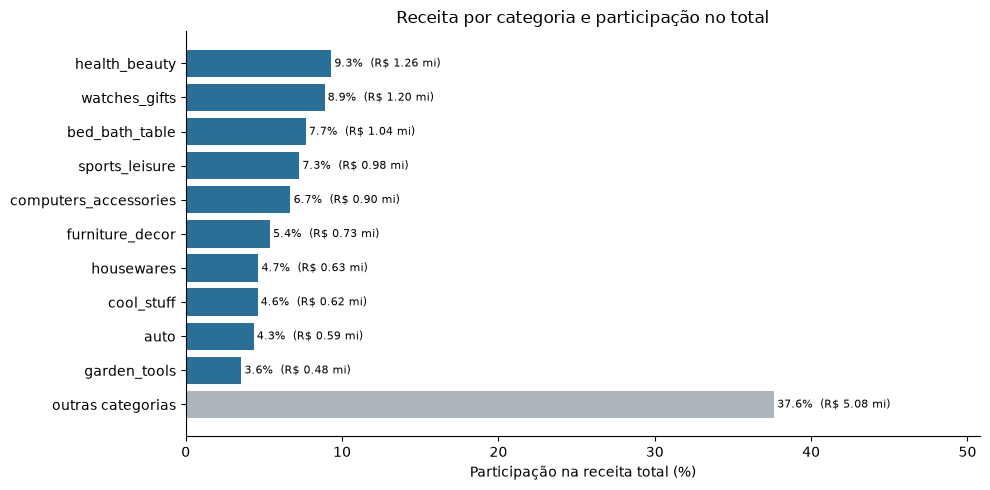

**Conclusão de negócio**

- As 10 maiores categorias respondem por 62.4% da receita; as outras 64 dividem 37.6%.
- Nenhuma categoria passa de 9.3% do total: a receita é pulverizada, sem dependência de um único segmento.
- A cauda longa de categorias pequenas sugere priorizar sortimento e estoque nas 10 primeiras, sem abandonar as demais.

In [8]:
df = q("q4a_receita_share_categoria"); display(df.head(15))
top = df.head(10).copy(); outras = df.iloc[10:]
top.loc[len(top)] = ["outras categorias", outras.receita.sum(), outras.pct.sum()]
fig, ax = plt.subplots(figsize=(10, 5)); cores = ["#2a6f97"] * 10 + ["#adb5bd"]
b = ax.barh(top.categoria[::-1], top.pct[::-1], color=cores[::-1])
for r, p, v in zip(b, top.pct[::-1], top.receita[::-1]): ax.text(r.get_width() + .2, r.get_y() + r.get_height() / 2, f"{p:.1f}%  (R$ {v/1e6:.2f} mi)", va="center", fontsize=8)
ax.set_xlabel("Participação na receita total (%)"); ax.set_xlim(0, top.pct.max() * 1.35); ax.set_title("Receita por categoria e participação no total"); save(fig, "04a_receita_share_categoria")
conclusao(f"As 10 maiores categorias respondem por {df.pct.head(10).sum():.1f}% da receita; as outras {len(df)-10} dividem {outras.pct.sum():.1f}%.",
          f"Nenhuma categoria passa de {df.pct.iloc[0]:.1f}% do total: a receita é pulverizada, sem dependência de um único segmento.",
          "A cauda longa de categorias pequenas sugere priorizar sortimento e estoque nas 10 primeiras, sem abandonar as demais.")

### 4b. Qual o valor médio do frete por estado do cliente?

-- Financeiro (4B): qual o valor médio do frete por estado do cliente?
SELECT c.state AS uf,
       round(avg(f.freight_value), 2) AS frete_medio,
       count(*) AS itens
FROM gold.fact_order_items f
JOIN gold.dim_customer c USING (customer_id)
WHERE f.is_revenue
GROUP BY 1
ORDER BY frete_medio DESC;


,uf,frete_medio,itens
0,RR,43.32,51
1,PB,42.75,600
2,RO,41.13,277
3,AC,40.07,92
4,PI,39.16,539
5,MA,38.29,820
6,TO,37.25,314
7,SE,36.65,385
8,AL,35.84,444
9,PA,35.83,1079


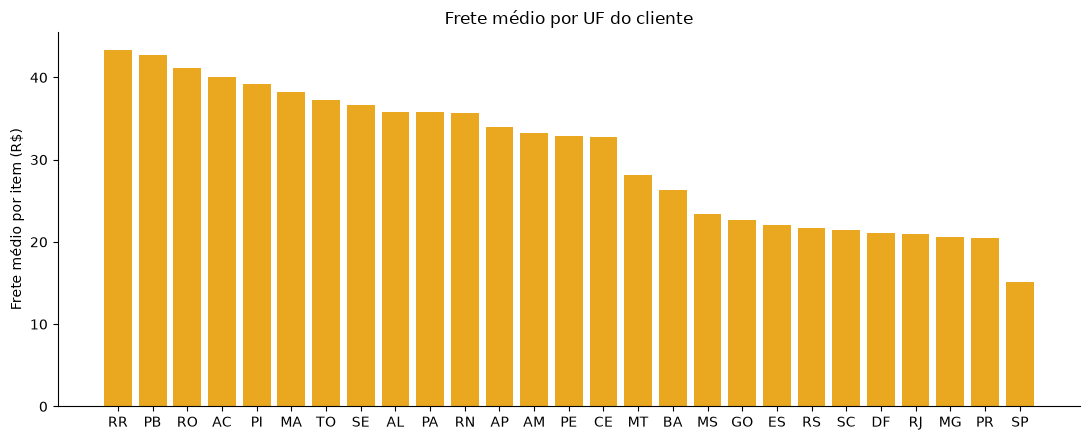

**Conclusão de negócio**

- O frete médio mais alto é em **RR** (R\$ 43.32) e o mais baixo em **SP** (R\$ 15.15).
- Diferença regional relevante no custo de entrega pode afetar conversão e competitividade nesses estados.
- Frete é valor por item; não é custo logístico real da operação.

In [9]:
df = q("q4_frete_medio_uf"); display(df)
fig, ax = plt.subplots(figsize=(11, 4.5)); ax.bar(df.uf, df.frete_medio, color="#e9a820")
ax.set_ylabel("Frete médio por item (R$)"); ax.set_title("Frete médio por UF do cliente"); save(fig, "04b_frete_medio_uf")
conclusao(f"O frete médio mais alto é em **{df.uf.iloc[0]}** (R$ {df.frete_medio.iloc[0]:.2f}) e o mais baixo em **{df.uf.iloc[-1]}** (R$ {df.frete_medio.iloc[-1]:.2f}).",
          "Diferença regional relevante no custo de entrega pode afetar conversão e competitividade nesses estados.",
          "Frete é valor por item; não é custo logístico real da operação.")

## Tópico 5: Clientes e pagamentos

### 5a. Qual a porcentagem de clientes que compraram mais de uma vez?

-- Clientes (5A): qual a porcentagem de clientes que compraram mais de uma vez?
-- Cliente = customer_unique_id (customer_id muda a cada pedido).
WITH por_cliente AS (
    SELECT c.customer_unique_id, count(DISTINCT o.order_id) AS pedidos
    FROM gold.fact_orders o
    JOIN gold.dim_customer c USING (customer_id)
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
    GROUP BY 1
)
SELECT CASE WHEN pedidos > 1 THEN 'Mais de uma compra' ELSE 'Uma compra' END AS perfil,
       count(*) AS clientes,
       round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
FROM por_cliente
GROUP BY 1
ORDER BY 1;


,perfil,clientes,pct
0,Mais de uma compra,2888,3.04
1,Uma compra,92102,96.96


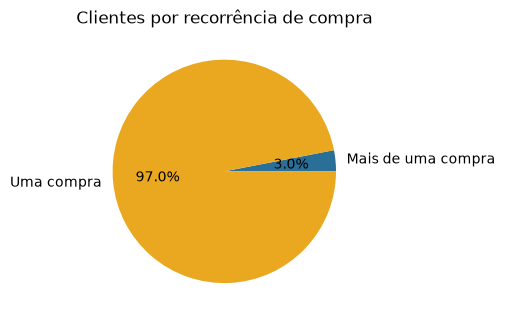

**Conclusão de negócio**

- Apenas 3.0% dos clientes compraram mais de uma vez.
- A base é dominada por compradores de uma única compra: há pouca retenção.
- Campanhas de recompra e pós-venda têm grande espaço de crescimento.

In [10]:
df = q("q5_clientes_recorrentes"); display(df)
fig, ax = plt.subplots(figsize=(5, 5)); ax.pie(df.clientes, labels=df.perfil, autopct="%1.1f%%", colors=["#2a6f97", "#e9a820"])
ax.set_title("Clientes por recorrência de compra"); save(fig, "05a_clientes_recorrentes")
r = df.set_index("perfil").pct
conclusao(f"Apenas {r['Mais de uma compra']:.1f}% dos clientes compraram mais de uma vez.",
          "A base é dominada por compradores de uma única compra: há pouca retenção.",
          "Campanhas de recompra e pós-venda têm grande espaço de crescimento.")

### 5b. Quais os meios de pagamento mais usados?

-- Clientes e pagamentos (5B): quais os meios de pagamento mais usados?
SELECT payment_type AS tipo,
       count(*) AS pagamentos,
       round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct,
       round(sum(payment_value), 2) AS valor
FROM gold.fact_payments
GROUP BY 1
ORDER BY pagamentos DESC;


,tipo,pagamentos,pct,valor
0,credit_card,76795,73.92,12542084.19
1,boleto,19784,19.04,2869361.27
2,voucher,5775,5.56,379436.87
3,debit_card,1529,1.47,217989.79


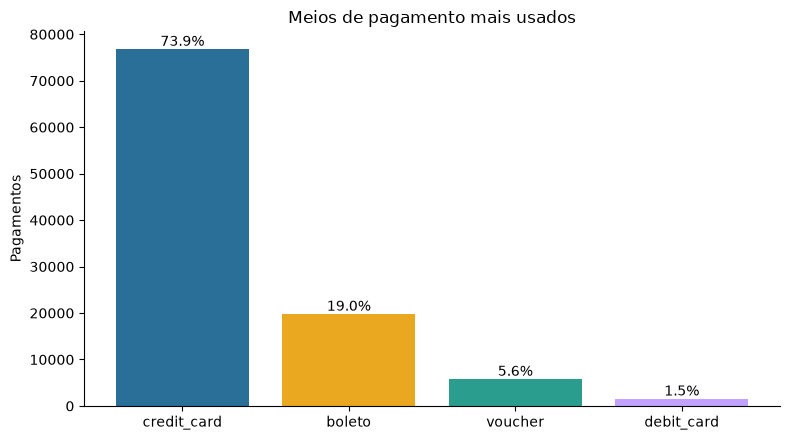

**Conclusão de negócio**

- O meio mais usado é **credit_card**, com 73.9% dos pagamentos, seguido de **boleto** (19.0%).
- Juntos, os dois somam 93.0% dos pagamentos; voucher e débito são marginais.
- A forte presença do cartão de crédito indica importância do parcelamento e de acordos com adquirentes.

In [11]:
df = q("q5b_meios_pagamento"); display(df)
fig, ax = plt.subplots(figsize=(8, 4.5)); b = ax.bar(df.tipo, df.pagamentos, color=["#2a6f97", "#e9a820", "#2a9d8f", "#c3a2ff", "#8b929a"][:len(df)])
for r, p in zip(b, df.pct): ax.text(r.get_x() + r.get_width() / 2, r.get_height(), f"{p:.1f}%", ha="center", va="bottom")
ax.set_ylabel("Pagamentos"); ax.set_title("Meios de pagamento mais usados"); save(fig, "05b_meios_pagamento")
conclusao(f"O meio mais usado é **{df.tipo[0]}**, com {df.pct[0]:.1f}% dos pagamentos, seguido de **{df.tipo[1]}** ({df.pct[1]:.1f}%).",
          f"Juntos, os dois somam {df.pct[0]+df.pct[1]:.1f}% dos pagamentos; voucher e débito são marginais.",
          "A forte presença do cartão de crédito indica importância do parcelamento e de acordos com adquirentes.")

## Limitações dos dados

- Não há **custo do produto** nem margem: toda análise é de **receita**, nunca de lucro.
- O dataset é uma amostra de um marketplace (2016 a 2018), não a operação completa de um varejista.
- Valores ausentes não foram imputados; pedidos sem data de entrega ficam sem prazo.
- Detalhes das regras de qualidade: `docs/data_quality.md`.